In [22]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [23]:
import os

os.environ["OMP_NUM_THREADS"] = "1"  # OpenMP
os.environ["MKL_NUM_THREADS"] = "1"  # MKL
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # OpenBLAS
os.environ["NUMEXPR_NUM_THREADS"] = "1"  # numexpr

In [24]:
import json
from pathlib import Path

import xarray as xr
from matplotlib import pyplot as plt

In [25]:
path_ftp = Path("/net/exo/landclim_nobackup/FTP/yhaddad/")

In [26]:
zarr_files = list(path_ftp.glob("recipe/*.zarr"))

In [45]:
zarr_files

[PosixPath('/net/exo/landclim_nobackup/FTP/yhaddad/recipe/pv_grid_2040.zarr'),
 PosixPath('/net/exo/landclim_nobackup/FTP/yhaddad/recipe/wind_power_grid_2040_E-126_7580.zarr')]

In [47]:
xr.open_zarr(zarr_files[1])

<xarray.Dataset> Size: 355MB
Dimensions:     (time: 248, lat: 426, lon: 420)
Coordinates:
  * lat         (lat) float64 3kB 30.05 30.15 30.25 30.35 ... 72.35 72.45 72.55
  * lon         (lon) float64 3kB -11.95 -11.85 -11.75 ... 29.75 29.85 29.95
  * time        (time) datetime64[ns] 2kB 2040-06-01 ... 2040-07-01T21:00:00
Data variables:
    E-126_7580  (time, lat, lon) float64 355MB dask.array<chunksize=(248, 128, 128), meta=np.ndarray>

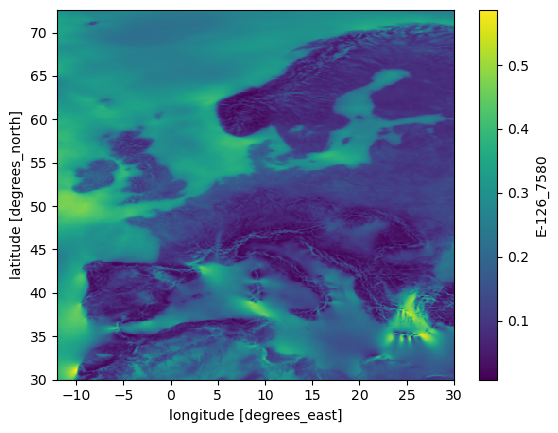

In [46]:
xr.open_zarr(zarr_files[1]).mean("time")['E-126_7580'].plot()
plt.show()

In [36]:
paths = json.load(open("../../paths_so4.json", "r"))
path_data_processed = Path(paths["path_data_processed"])

In [41]:
wind_power_zarr = list((path_data_processed / "energy" / "europe" / "wind_power").glob("CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85/*.zarr"))

In [48]:
wind_power_zarr

[PosixPath('/net/exo/landclim/yhaddad/clim2energy-ch/energy/europe/wind_power/CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85/wind_power_CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85_E-126_7580.zarr'),
 PosixPath('/net/exo/landclim/yhaddad/clim2energy-ch/energy/europe/wind_power/CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85/wind_power_CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85_SWT120_3600.zarr'),
 PosixPath('/net/exo/landclim/yhaddad/clim2energy-ch/energy/europe/wind_power/CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85/wind_power_CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85_SWT142_3150.zarr')]

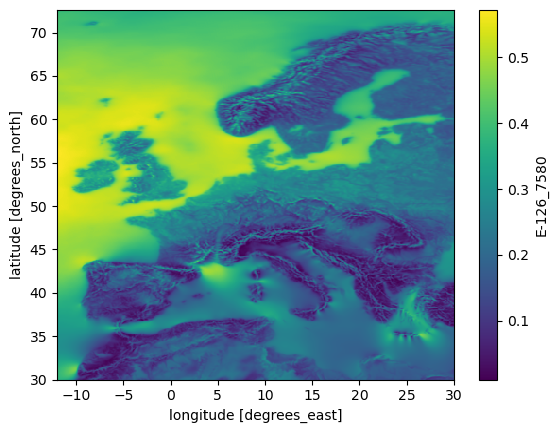

In [44]:
xr.open_zarr(wind_power_zarr[0]).sel(time="2040").mean(dim="time")['E-126_7580'].plot()

In [54]:
xr.open_zarr(path_data_processed / "cordex_processed" / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85" / "bias_corrected" / "3hr" / "wind100m.zarr")

<xarray.Dataset> Size: 228GB
Dimensions:   (lat: 426, lon: 420, time: 318280)
Coordinates:
  * lat       (lat) float64 3kB 30.05 30.15 30.25 30.35 ... 72.35 72.45 72.55
  * lon       (lon) float64 3kB -11.95 -11.85 -11.75 ... 29.75 29.85 29.95
  * time      (time) datetime64[ns] 3MB 1991-01-01 ... 2099-12-31T21:00:00
Data variables:
    wind100m  (time, lat, lon) float32 228GB dask.array<chunksize=(2920, 128, 128), meta=np.ndarray>
Attributes: (12/31)
    CDI:                            Climate Data Interface version 2.4.0 (htt...
    CDO:                            Climate Data Operators version 2.4.0 (htt...
    CORDEX_domain:                  EUR-11
    Conventions:                    CF-1.6
    bias_adjustment:                EmpiricalQuantileMapping(group=Grouper(na...
    c3s_disclaimer:                 This data has been produced in the contex...
    ...                             ...
    project_id:                     CORDEX
    rcm_version_id:                 v2
    reference_period:               1991 - 2020
    references:                     http://www.umr-cnrm.fr/spip.php?article12...
    title:                          Created by xios
    tracking_id:                    hdl:21.14103/682beae0-1590-47ed-ba7a-d2f0...

In [55]:
xr.open_zarr(path_data_processed / "cordex_processed" / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85" / "bias_corrected" / "3hr" / "tas.zarr")

<xarray.Dataset> Size: 389GB
Dimensions:  (lat: 426, lon: 710, time: 321200)
Coordinates:
  * lat      (lat) float64 3kB 30.05 30.15 30.25 30.35 ... 72.35 72.45 72.55
  * lon      (lon) float64 6kB -29.95 -29.85 -29.75 -29.65 ... 40.75 40.85 40.95
  * time     (time) datetime64[ns] 3MB 1991-01-01 ... 2100-12-31T21:00:00
Data variables:
    tas      (time, lat, lon) float32 389GB dask.array<chunksize=(2920, 128, 128), meta=np.ndarray>
Attributes: (12/32)
    CDI:                            Climate Data Interface version 2.4.0 (htt...
    CDO:                            Climate Data Operators version 2.4.0 (htt...
    CORDEX_domain:                  EUR-11
    Convention:                     CF-1.6
    Conventions:                    CF-1.6
    bias_adjustment:                EmpiricalQuantileMapping(group=Grouper(na...
    ...                             ...
    project_id:                     CORDEX
    rcm_version_id:                 v2
    reference_period:               1991 - 2020
    references:                     http://www.umr-cnrm.fr/spip.php?article12...
    title:                          Created by xios
    tracking_id:                    hdl:21.14103/b5f438d4-cd97-40cf-b3d7-6c05...

In [58]:
wind100m_zarr_files = list((path_data_processed / "cordex_processed").glob("*/bias_corrected/3hr/wind100m.zarr"))

In [59]:
xr.open_zarr(wind100m_zarr_files[2])

<xarray.Dataset> Size: 385GB
Dimensions:   (lat: 426, lon: 710, time: 318281)
Coordinates:
  * lat       (lat) float64 3kB 30.05 30.15 30.25 30.35 ... 72.35 72.45 72.55
  * lon       (lon) float64 6kB -29.95 -29.85 -29.75 ... 40.75 40.85 40.95
  * time      (time) datetime64[ns] 3MB 1991-01-01 ... 2100-01-01
Data variables:
    wind100m  (time, lat, lon) float32 385GB dask.array<chunksize=(2920, 128, 128), meta=np.ndarray>
Attributes: (12/30)
    CDI:                            Climate Data Interface version 2.4.0 (htt...
    CDO:                            Climate Data Operators version 2.4.0 (htt...
    CORDEX_domain:                  EUR-11
    Conventions:                    CF-1.6
    bias_adjustment:                EmpiricalQuantileMapping(group=Grouper(na...
    c3s_disclaimer:                 This data has been produced in the contex...
    ...                             ...
    project_id:                     CORDEX
    rcm_version_id:                 v1
    reference_period:               1991 - 2020
    references:                     http://www.umr-cnrm.fr/spip.php?article12...
    title:                          Created by xios
    tracking_id:                    hdl:21.14103/c421f349-ebe2-4a87-b5a6-7762...